# Investigate SNN activity

Load a trained `event_frame_snn` checkpoint and inspect per-layer spike / membrane
activity across the shallow 2-LIF encoder (`lif1`, `lif2`) that predicts a
full-resolution heatmap.

**Sample selection:** edit `SAMPLE_IDX` (and optionally `SPLIT` / `BATCH_SIZE`) in
the next cell, then re-run from there.

Uses `BallHeatmapSNN.forward_with_activity` + `horus.eval.snn_activity`.

**Note:** retrain after the full-res heatmap change — old coord-head
`event_frame_snn.pt` checkpoints will not load.


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

from horus.config import load_config, repo_root
from horus.convert.frame_diff import load_rgb
from horus.data.dataset import build_dataloader
from horus.eval import ARCH_REGISTRY, load_model, summarize_activity
from horus.models import pred_to_pixel_coords
from horus.models.snn import LAYER_NAMES, BallHeatmapSNN

# =============================================================================
# Sample selection — change these, then re-run this cell and below
# =============================================================================
SPLIT = "val"          # "train" | "val" | "test"
SAMPLE_IDX = 100         # dataset index for detail views (browse failures here)
BATCH_SIZE = 16    # samples in the comparison grid starting at SAMPLE_IDX
LIMIT_SAMPLES = None   # None = full split; set an int to cap (e.g. 8 for overfit)
TOP_K_CHANNELS = 8
# =============================================================================

ARCH = "event_frame_snn"
ROOT = repo_root()
cfg = load_config()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

_, modality = ARCH_REGISTRY[ARCH]
ckpt_path = ROOT / "checkpoints" / "event_frame_snn.pt"
if not ckpt_path.is_file():
    raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

ckpt_meta = torch.load(ckpt_path, map_location="cpu", weights_only=True)
steps = int(ckpt_meta.get("steps", cfg["sequence"]["length"]))
repeat_frame = bool(ckpt_meta.get("repeat_frame", False))
# load_model reads steps / drop_last_lif from the checkpoint (not ARCH_REGISTRY defaults).
model = load_model(ARCH, ckpt_path, device)
assert isinstance(model, BallHeatmapSNN)
assert model.steps == steps, f"model.steps={model.steps} != ckpt steps={steps}"
print(
    f"arch={ARCH} modality={modality} steps={steps} in_ch={2 * steps} "
    f"epoch={ckpt_meta.get('epoch')} val_px={ckpt_meta.get('val_px')} device={device}"
)

full_loader = build_dataloader(
    cfg,
    SPLIT,
    modality,
    batch_size=1,
    num_workers=0,
    shuffle=False,
    repeat_frame=repeat_frame,
    input_steps=steps,
)
base_ds = full_loader.dataset

# Optional cap: explicit LIMIT_SAMPLES wins; else honor overfit ckpt max_samples.
cap = LIMIT_SAMPLES
if cap is None and ckpt_meta.get("max_samples") is not None:
    cap = int(ckpt_meta["max_samples"])
if cap is not None:
    n_keep = min(int(cap), len(base_ds))
    ds = Subset(base_ds, list(range(n_keep)))
else:
    ds = base_ds

n_ds = len(ds)
if SAMPLE_IDX < 0 or SAMPLE_IDX >= n_ds:
    raise IndexError(f"SAMPLE_IDX={SAMPLE_IDX} out of range for split={SPLIT} (n={n_ds})")

batch_indices = list(range(SAMPLE_IDX, min(SAMPLE_IDX + BATCH_SIZE, n_ds)))
loader = DataLoader(
    Subset(ds, batch_indices),
    batch_size=len(batch_indices),
    shuffle=False,
    num_workers=0,
)
batch = next(iter(loader))
# Detail sample is always index 0 in this batch (= SAMPLE_IDX in the dataset).
i = 0
print(
    f"split={SPLIT} dataset_n={n_ds} sample_idx={SAMPLE_IDX} "
    f"batch_indices={batch_indices} steps={steps} repeat_frame={repeat_frame}"
)
print(
    f"detail: {batch['game'][i]}/{batch['clip'][i]} frame={batch['frame'][i]} "
    f"end_idx={int(batch['end_idx'][i])} visible={float(batch['visible'][i]):.0f}"
)

x = batch["input"].to(device)
with torch.no_grad():
    pred, trace = model.forward_with_activity(x)
    pred = pred.cpu()
gt, coords = batch["heatmap"], batch["coords"]
_, _, H, W = x.shape
pred_xy = pred_to_pixel_coords(pred, height=H, width=W)
stats = summarize_activity(trace)


def preview_event_step(chw: torch.Tensor, t: int) -> np.ndarray:
    """Polarity pair at timestep t as R=pos, B=neg."""
    arr = chw.detach().float().cpu().numpy()
    pos, neg = arr[2 * t], arr[2 * t + 1]
    scale = max(float(pos.max()), float(neg.max()), 1e-8)
    rgb = np.zeros((*pos.shape, 3), dtype=np.float32)
    rgb[..., 0] = pos / scale
    rgb[..., 2] = neg / scale
    return np.clip(rgb, 0, 1)


def preview_event(chw: torch.Tensor) -> np.ndarray:
    """Last polarity pair (label-aligned frame)."""
    n_steps = chw.shape[0] // 2
    return preview_event_step(chw, n_steps - 1)


def load_rgb_window_for_index(dataset_index: int) -> list[np.ndarray]:
    """RGB frames for the temporal window that produced this sample."""
    # Map through Subset chain back to base BallTrackDataset index.
    idx = dataset_index
    d = ds
    while isinstance(d, Subset):
        idx = int(d.indices[idx])
        d = d.dataset
    sample = d[idx]
    clip = d.clip_map[f"{sample['game']}/{sample['clip']}"]
    end_idx = int(sample["end_idx"])
    seq_len = int(d.seq_len)
    start = end_idx - seq_len + 1
    return [
        load_rgb(str(clip.frames[j]), d.out_w, d.out_h)
        for j in range(start, end_idx + 1)
    ]


rgb_windows = [load_rgb_window_for_index(j) for j in batch_indices]
print(f"loaded RGB windows: {[len(w) for w in rgb_windows]} frames each")


arch=event_frame_snn modality=event_frame steps=5 in_ch=10 epoch=16 val_px=85.02968970479087 device=cuda
split=val dataset_n=3459 sample_idx=100 batch_indices=[100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115] steps=5 repeat_frame=False
detail: game8/Clip1 frame=0104.jpg end_idx=104 visible=1
loaded RGB windows: [5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5] frames each


## Per-layer activity metrics

- **mean_membrane** — average pre-reset potential  
- **spike_frac** — fraction of neurons that fire at least once in the window  
- **rate** — spikes per neuron per timestep  
- **silent** — never fire (dead units)  
- **hyper** — fire on nearly every timestep (default threshold 0.9 → all steps)


In [8]:
print(f"{'layer':<14} {'mean_v':>8} {'spike%':>8} {'rate':>8} {'silent%':>8} {'hyper%':>8}")
print("-" * 58)
for name in LAYER_NAMES:
    m = stats[name]
    print(
        f"{name:<14} {m['mean_membrane']:8.4f} {100*m['spike_frac']:7.2f}% "
        f"{m['spikes_per_neuron_per_timestep']:8.4f} {100*m['silent_frac']:7.2f}% "
        f"{100*m['hyperactive_frac']:7.2f}%"
    )


layer            mean_v   spike%     rate  silent%   hyper%
----------------------------------------------------------
lif1            -0.0580    9.51%   0.0275   90.49%    0.40%
lif2            -0.4007   27.63%   0.0798   72.37%    1.54%


## Input frames (event + RGB)

All event-frame polarity pairs fed to the SNN for `SAMPLE_IDX`, plus the
matching RGB frames from the dataset (same temporal window; last frame is the
labeled one).


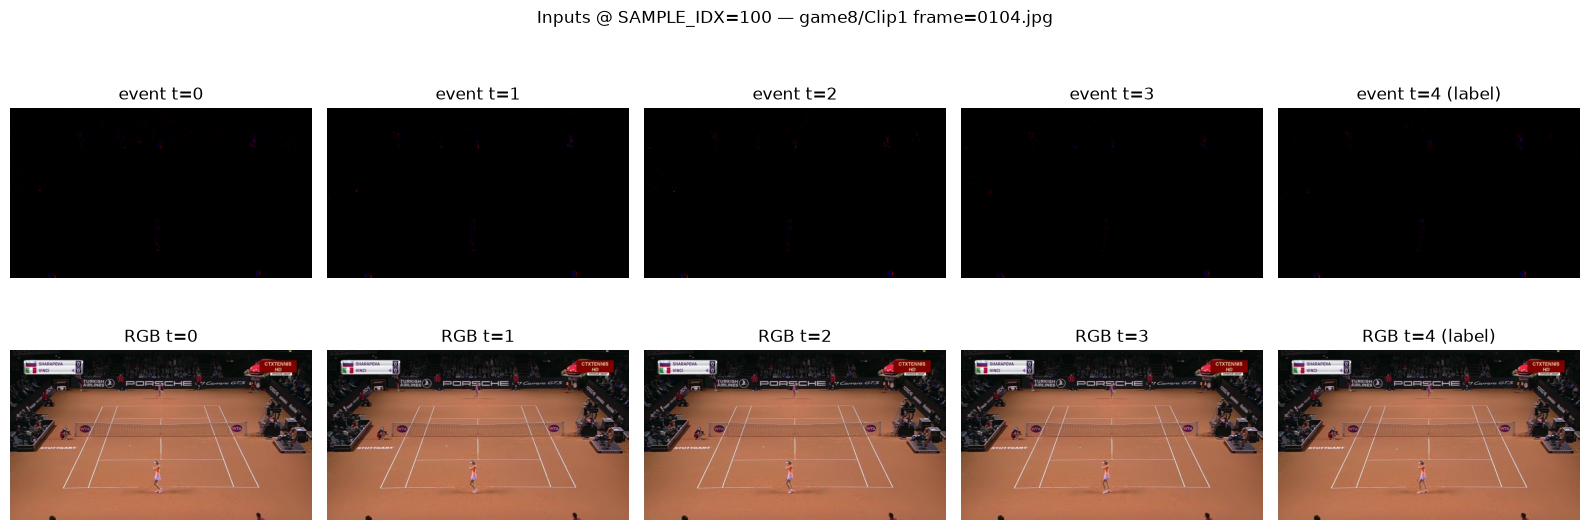

In [9]:
# Event inputs for the detail sample
event_frames = [preview_event_step(batch["input"][i], t) for t in range(steps)]
rgb_frames = rgb_windows[i]
assert len(rgb_frames) == steps or repeat_frame

n_cols = max(steps, 1)
fig, axes = plt.subplots(2, n_cols, figsize=(3.2 * n_cols, 6.0))
if n_cols == 1:
    axes = np.array([[axes[0]], [axes[1]]])

for t in range(n_cols):
    axes[0, t].imshow(event_frames[min(t, len(event_frames) - 1)])
    axes[0, t].set_title(f"event t={t}" + (" (label)" if t == steps - 1 else ""))
    axes[0, t].axis("off")
    rgb_t = rgb_frames[min(t, len(rgb_frames) - 1)]
    axes[1, t].imshow(rgb_t)
    axes[1, t].set_title(f"RGB t={t}" + (" (label)" if t == steps - 1 else ""))
    axes[1, t].axis("off")

fig.suptitle(
    f"Inputs @ SAMPLE_IDX={SAMPLE_IDX} — "
    f"{batch['game'][i]}/{batch['clip'][i]} frame={batch['frame'][i]}",
    fontsize=12,
)
plt.tight_layout()
plt.show()


## Layer representations

For `SAMPLE_IDX`: last-event preview, mean spike-rate / membrane maps per LIF,
then GT / pred overlay. Top-k channels follow.


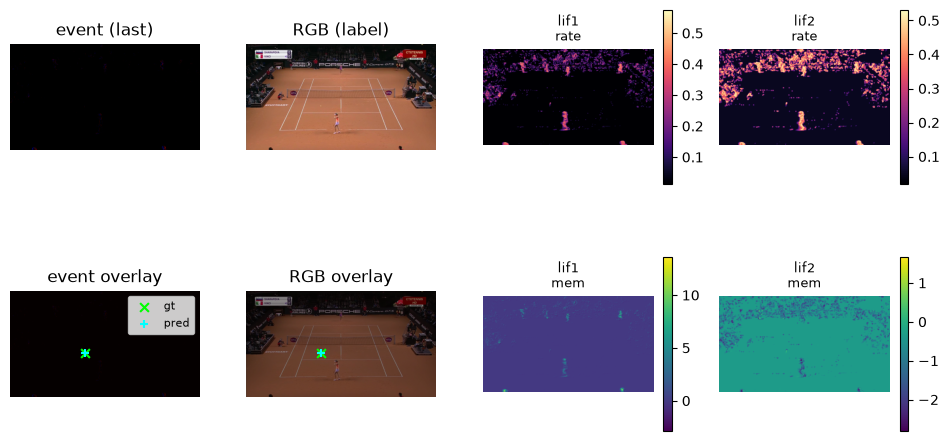

SAMPLE_IDX=100  gt=(252.5,210.5)  pred=(252.0,209.0)  err_px=1.6


In [10]:
def spatial_mean(t: torch.Tensor) -> np.ndarray:
    """(T, C, H, W) → mean over T and C → (H, W)."""
    return t.float().mean(dim=(0, 1)).cpu().numpy()


def top_channel_maps(spikes: torch.Tensor, k: int) -> tuple[np.ndarray, list[int]]:
    """Return (k, H, W) maps for the k channels with highest mean rate."""
    rates = spikes.float().mean(dim=(0, 2, 3))  # (C,)
    k = min(k, rates.numel())
    idx = torch.topk(rates, k).indices.tolist()
    maps = spikes[:, idx].float().mean(dim=0).cpu().numpy()  # (k, H, W)
    return maps, idx


STAGE_LIF = tuple(LAYER_NAMES)

frame = preview_event(batch["input"][i])
rgb_last = rgb_windows[i][-1]
g = gt[i, 0].numpy()
p = pred[i, 0].numpy()
gx, gy = coords[i].tolist()
px, py = pred_xy[i].tolist()

n_stage = len(STAGE_LIF)
fig, axes = plt.subplots(2, n_stage + 2, figsize=(2.4 * (n_stage + 2), 5.5))

axes[0, 0].imshow(frame)
axes[0, 0].set_title("event (last)")
axes[0, 1].imshow(rgb_last)
axes[0, 1].set_title("RGB (label)")

for col, name in enumerate(STAGE_LIF, start=2):
    layer = trace[name]
    rate_map = spatial_mean(layer.spikes[i])
    mem_map = spatial_mean(layer.membrane[i])
    im = axes[0, col].imshow(rate_map, cmap="magma")
    axes[0, col].set_title(f"{name}\nrate", fontsize=9)
    fig.colorbar(im, ax=axes[0, col], fraction=0.046)
    im = axes[1, col].imshow(mem_map, cmap="viridis")
    axes[1, col].set_title(f"{name}\nmem", fontsize=9)
    fig.colorbar(im, ax=axes[1, col], fraction=0.046)

axes[1, 0].imshow(frame)
axes[1, 0].imshow(p, cmap="hot", alpha=0.55, vmin=0, vmax=1)
axes[1, 0].scatter([gx], [gy], c="lime", s=40, marker="x", label="gt")
axes[1, 0].scatter([px], [py], c="cyan", s=40, marker="+", label="pred")
axes[1, 0].set_title("event overlay")
axes[1, 0].legend(loc="upper right", fontsize=8)

axes[1, 1].imshow(rgb_last)
axes[1, 1].imshow(p, cmap="hot", alpha=0.45, vmin=0, vmax=1)
axes[1, 1].scatter([gx], [gy], c="lime", s=40, marker="x")
axes[1, 1].scatter([px], [py], c="cyan", s=40, marker="+")
axes[1, 1].set_title("RGB overlay")

for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

err = float(np.hypot(px - gx, py - gy))
print(f"SAMPLE_IDX={SAMPLE_IDX}  gt=({gx:.1f},{gy:.1f})  pred=({px:.1f},{py:.1f})  err_px={err:.1f}")


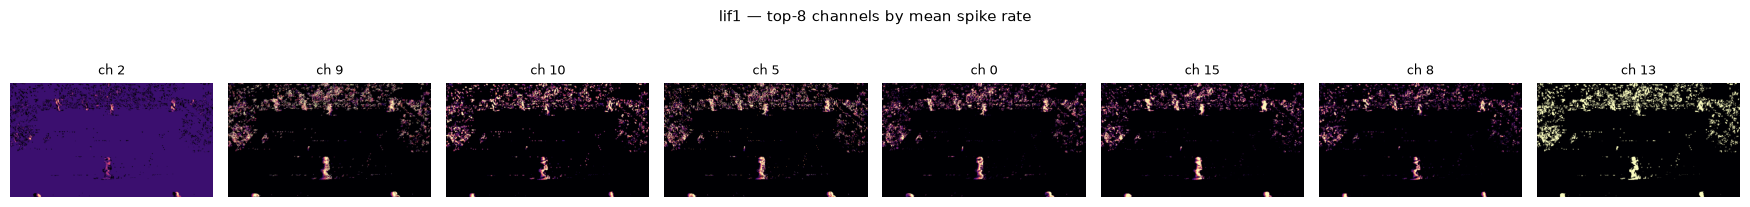

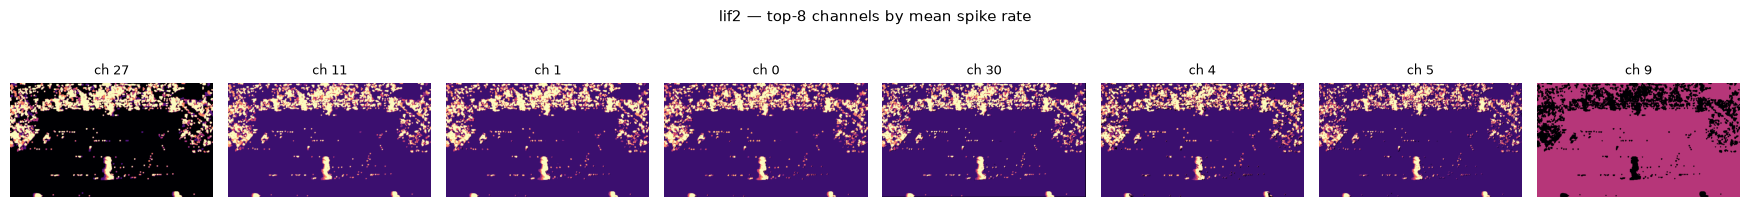

In [11]:
# Top-k most active channels per LIF (detail sample)
for name in LAYER_NAMES:
    layer = trace[name]
    maps, idxs = top_channel_maps(layer.spikes[i], TOP_K_CHANNELS)
    k = maps.shape[0]
    fig, axes = plt.subplots(1, k, figsize=(2.2 * k, 2.4))
    if k == 1:
        axes = [axes]
    for ax, ch_map, ch in zip(axes, maps, idxs):
        ax.imshow(ch_map, cmap="magma")
        ax.set_title(f"ch {ch}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{name} — top-{k} channels by mean spike rate", fontsize=11)
    plt.tight_layout()
    plt.show()


## Batch grid

Samples `SAMPLE_IDX … SAMPLE_IDX + BATCH_SIZE - 1`. Bump `SAMPLE_IDX` to walk
through the split.


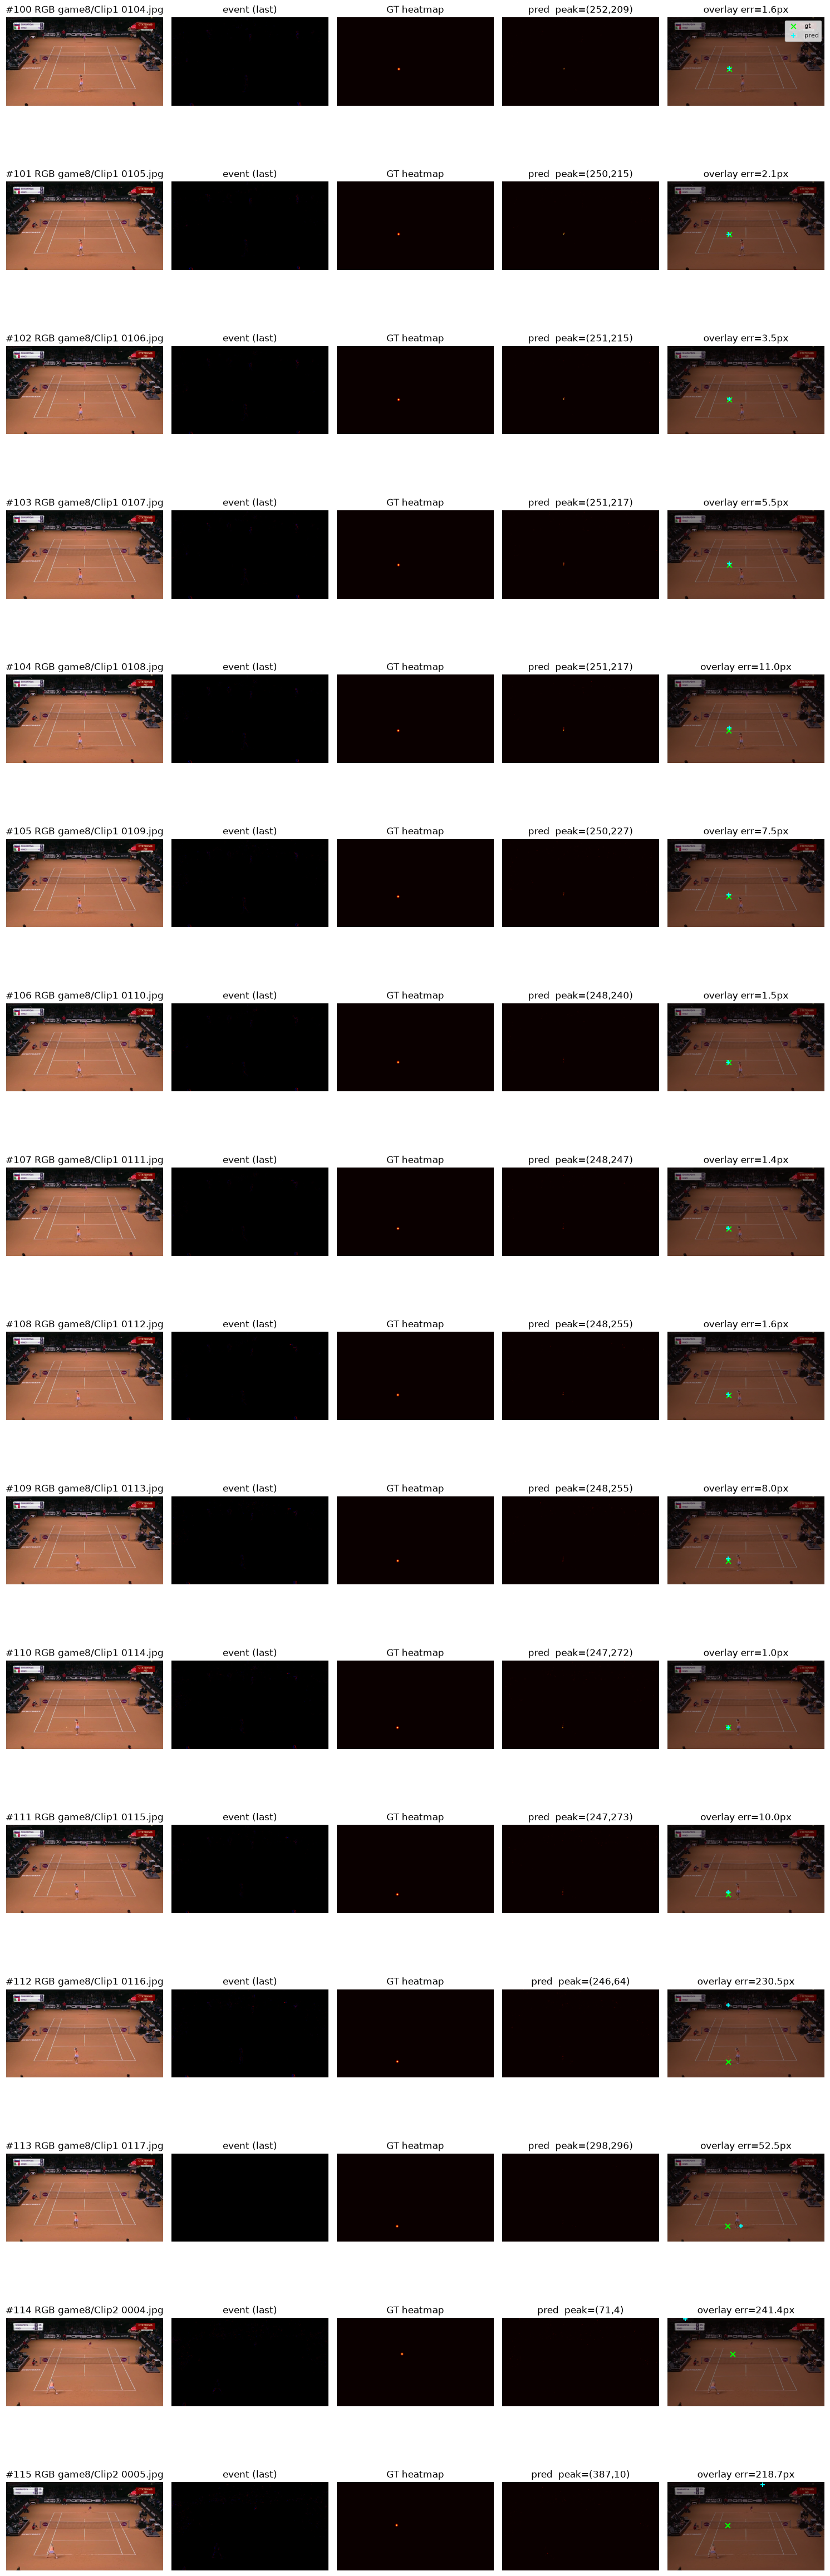

In [12]:
# Batch grid: RGB | event | GT | pred | overlay
n = pred.shape[0]
fig, axes = plt.subplots(n, 5, figsize=(15, 3 * n))
if n == 1:
    axes = axes[None, :]

for j in range(n):
    fr = preview_event(batch["input"][j])
    rgb_j = rgb_windows[j][-1]
    gj, pj = gt[j, 0].numpy(), pred[j, 0].numpy()
    gxj, gyj = coords[j].tolist()
    pxj, pyj = pred_xy[j].tolist()
    ds_idx = batch_indices[j]
    err_j = float(np.hypot(pxj - gxj, pyj - gyj))

    axes[j, 0].imshow(rgb_j)
    axes[j, 0].set_title(f"#{ds_idx} RGB {batch['game'][j]}/{batch['clip'][j]} {batch['frame'][j]}")
    axes[j, 1].imshow(fr)
    axes[j, 1].set_title("event (last)")
    axes[j, 2].imshow(gj, cmap="hot", vmin=0, vmax=1)
    axes[j, 2].set_title("GT heatmap")
    axes[j, 3].imshow(pj, cmap="hot", vmin=0, vmax=1)
    axes[j, 3].set_title(f"pred  peak=({pxj:.0f},{pyj:.0f})")
    axes[j, 4].imshow(rgb_j)
    axes[j, 4].imshow(pj, cmap="hot", alpha=0.45, vmin=0, vmax=1)
    axes[j, 4].scatter([gxj], [gyj], c="lime", s=40, marker="x", label="gt")
    axes[j, 4].scatter([pxj], [pyj], c="cyan", s=40, marker="+", label="pred")
    axes[j, 4].set_title(f"overlay err={err_j:.1f}px")
    if j == 0:
        axes[j, 4].legend(loc="upper right", fontsize=8)

for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()
